# Improving the Best Model — From R2 = 0.58 to as High as Possible

## What this notebook does

Our best model (Random Forest) got **R2 = 0.58**, meaning it explains 58% of complaint variation.
The remaining 42% is still unexplained. This notebook attacks that gap from **4 directions**:

| Step | Technique | What it does |
|---|---|---|
| 1 | Baseline audit | Understand WHY R2 is 0.58 before blindly tuning |
| 2 | Smarter features | Add features the original model never saw |
| 3 | Hyperparameter tuning | Systematically find the best model settings using Optuna |
| 4 | Stacking (ensemble) | Combine multiple models so their strengths cover each other's weaknesses |
| 5 | Final comparison | Show exactly how much each step improved R2 |

**Plain English principle behind all of this:**
> R2 = 0.58 means the model's errors are still somewhat predictable.
> If errors are predictable, we can build a second model ON TOP of the first to fix them.
> That is the core idea behind stacking.


## Step 0 — Setup: Load Everything from the Previous Pipeline

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings, time
warnings.filterwarnings('ignore')

from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                               ExtraTreesRegressor, StackingRegressor)
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.inspection import permutation_importance
import lightgbm as lgb
import xgboost as xgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)  # keep output clean

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': '#f9f9f9',
    'axes.grid': True, 'grid.alpha': 0.3,
    'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold'
})
SEED = 42
np.random.seed(SEED)
print("All libraries loaded!")


All libraries loaded!


In [2]:
# ── Reproduce the full feature-engineered dataset ────────────────────────
import holidays

import os
data_path = "../data/modeling_table_final.csv" if os.path.exists("../data/modeling_table_final.csv") else ("data/modeling_table_final.csv" if os.path.exists("data/modeling_table_final.csv") else "modeling_table_final.csv")
df = pd.read_csv(data_path)
df['date'] = pd.to_datetime(df['date'])
df = df.dropna(subset=['borough']).sort_values('date').reset_index(drop=True)

# Time features
df['month']       = df['date'].dt.month
df['day_of_week'] = df['date'].dt.dayofweek
df['month_sin']   = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos']   = np.cos(2 * np.pi * df['month'] / 12)
df['day_sin']     = np.sin(2 * np.pi * df['day_of_week'] / 7)
df['day_cos']     = np.cos(2 * np.pi * df['day_of_week'] / 7)

# Temperature range
if 'tmax' in df.columns and 'tmin' in df.columns:
    df['temp_range'] = df['tmax'] - df['tmin']

# Holiday flag
us_hols = holidays.UnitedStates(years=df['date'].dt.year.unique().tolist())
df['is_holiday'] = df['date'].isin(us_hols).astype(int)

# Interaction & trend
if 'prcp' in df.columns and 'water_breaks_ever' in df.columns:
    df['rain_x_infra'] = df['prcp'] * df['water_breaks_ever']

if 'rolling_avg_7d' in df.columns:
    df_s = df.sort_values(['incident_zip','date'])
    r30  = df_s.groupby('incident_zip')['request_count'].transform(
               lambda x: x.shift(1).rolling(30, min_periods=10).mean())
    df['rolling_avg_30d']  = r30.values
    df['trend_velocity']   = df['rolling_avg_7d'] - df['rolling_avg_30d']

# Log target
df['target'] = np.log1p(df['request_count'])

# Drop redundant
drop_cols = ['tmax','tmin','day_of_year','prcp_cat','request_count_log']
df.drop(columns=[c for c in drop_cols if c in df.columns], inplace=True)

# Encode zip
le = LabelEncoder()
df['zip_encoded'] = le.fit_transform(df['incident_zip'].astype(str))

# Feature matrix
DROP_FROM_X = ['request_count','target','date','borough','incident_zip']
feature_cols = [c for c in df.columns
                if c not in DROP_FROM_X
                and df[c].dtype in ['int64','float64','float32','int32']]

X = df[feature_cols].fillna(df[feature_cols].median())
y = df['target']

print(f"Dataset ready: {X.shape[0]:,} rows x {X.shape[1]} features")
print(f"Features: {list(X.columns)}")


Dataset ready: 160,951 rows x 30 features
Features: ['complaint_type_count', 'year', 'month', 'day_of_week', 'season', 'is_weekend', 'is_holiday', 'prcp', 'snow', 'snwd', 'awnd', 'temp_range', 'lag_request_1d', 'lag_request_7d', 'lag_request_14d', 'rolling_avg_7d', 'rolling_avg_30d', 'rolling_prcp_3d', 'freeze_thaw_7d', 'population', 'avg_pavement_rating', 'water_breaks_ever', 'water_breaks_30d', 'month_sin', 'month_cos', 'day_sin', 'day_cos', 'rain_x_infra', 'trend_velocity', 'zip_encoded']


In [3]:
# ── Helper: evaluate any model with TimeSeriesSplit ──────────────────────
def tscv_score(model, X_data, y_data, n_splits=5, verbose=False):
    tscv = TimeSeriesSplit(n_splits=n_splits)
    r2s, maes = [], []
    for fold, (tr, te) in enumerate(tscv.split(X_data)):
        Xtr = X_data.iloc[tr] if hasattr(X_data,'iloc') else X_data[tr]
        Xte = X_data.iloc[te] if hasattr(X_data,'iloc') else X_data[te]
        ytr = y_data.iloc[tr]; yte = y_data.iloc[te]
        model.fit(Xtr, ytr)
        yp  = model.predict(Xte)
        r2s.append(r2_score(yte, yp))
        maes.append(mean_absolute_error(np.expm1(yte), np.expm1(np.clip(yp,0,20))))
        if verbose: print(f"  Fold {fold+1}: R2={r2s[-1]:.4f}")
    return np.mean(r2s), np.std(r2s), np.mean(maes)

# ── Baseline: re-confirm the original Random Forest score ────────────────
print("Confirming baseline Random Forest score...")
baseline_rf = RandomForestRegressor(n_estimators=200, max_depth=12,
                                     min_samples_leaf=5, random_state=SEED, n_jobs=-1)
base_r2, base_std, base_mae = tscv_score(baseline_rf, X, y)
print(f"Baseline Random Forest  R2 = {base_r2:.4f} +/- {base_std:.4f}  |  MAE = {base_mae:.2f}")
print(f"This is our starting point. Every improvement will be measured against this.")

# Track all results for the final comparison chart
improvement_log = [{'Step': 'Baseline RF', 'R2': base_r2, 'MAE': base_mae, 'Note': 'Default hyperparams'}]


Confirming baseline Random Forest score...
Baseline Random Forest  R2 = 0.5864 +/- 0.0135  |  MAE = 1.44
This is our starting point. Every improvement will be measured against this.


## Step 1 — Baseline Audit: WHY is R2 only 0.58?

Before tuning blindly, we diagnose the problem.
A model stuck at R2 = 0.58 is failing in one of these ways:
1. **Wrong features** — it does not have the information it needs
2. **Bad hyperparameters** — the model is too simple or too overfit
3. **Structural errors in the predictions** — it is systematically wrong in certain conditions

We check all three with charts.


Computing permutation importance (takes ~30s)...
Features with negative importance (consider dropping): ['rolling_prcp_3d', 'rolling_avg_30d', 'snow', 'freeze_thaw_7d', 'year']


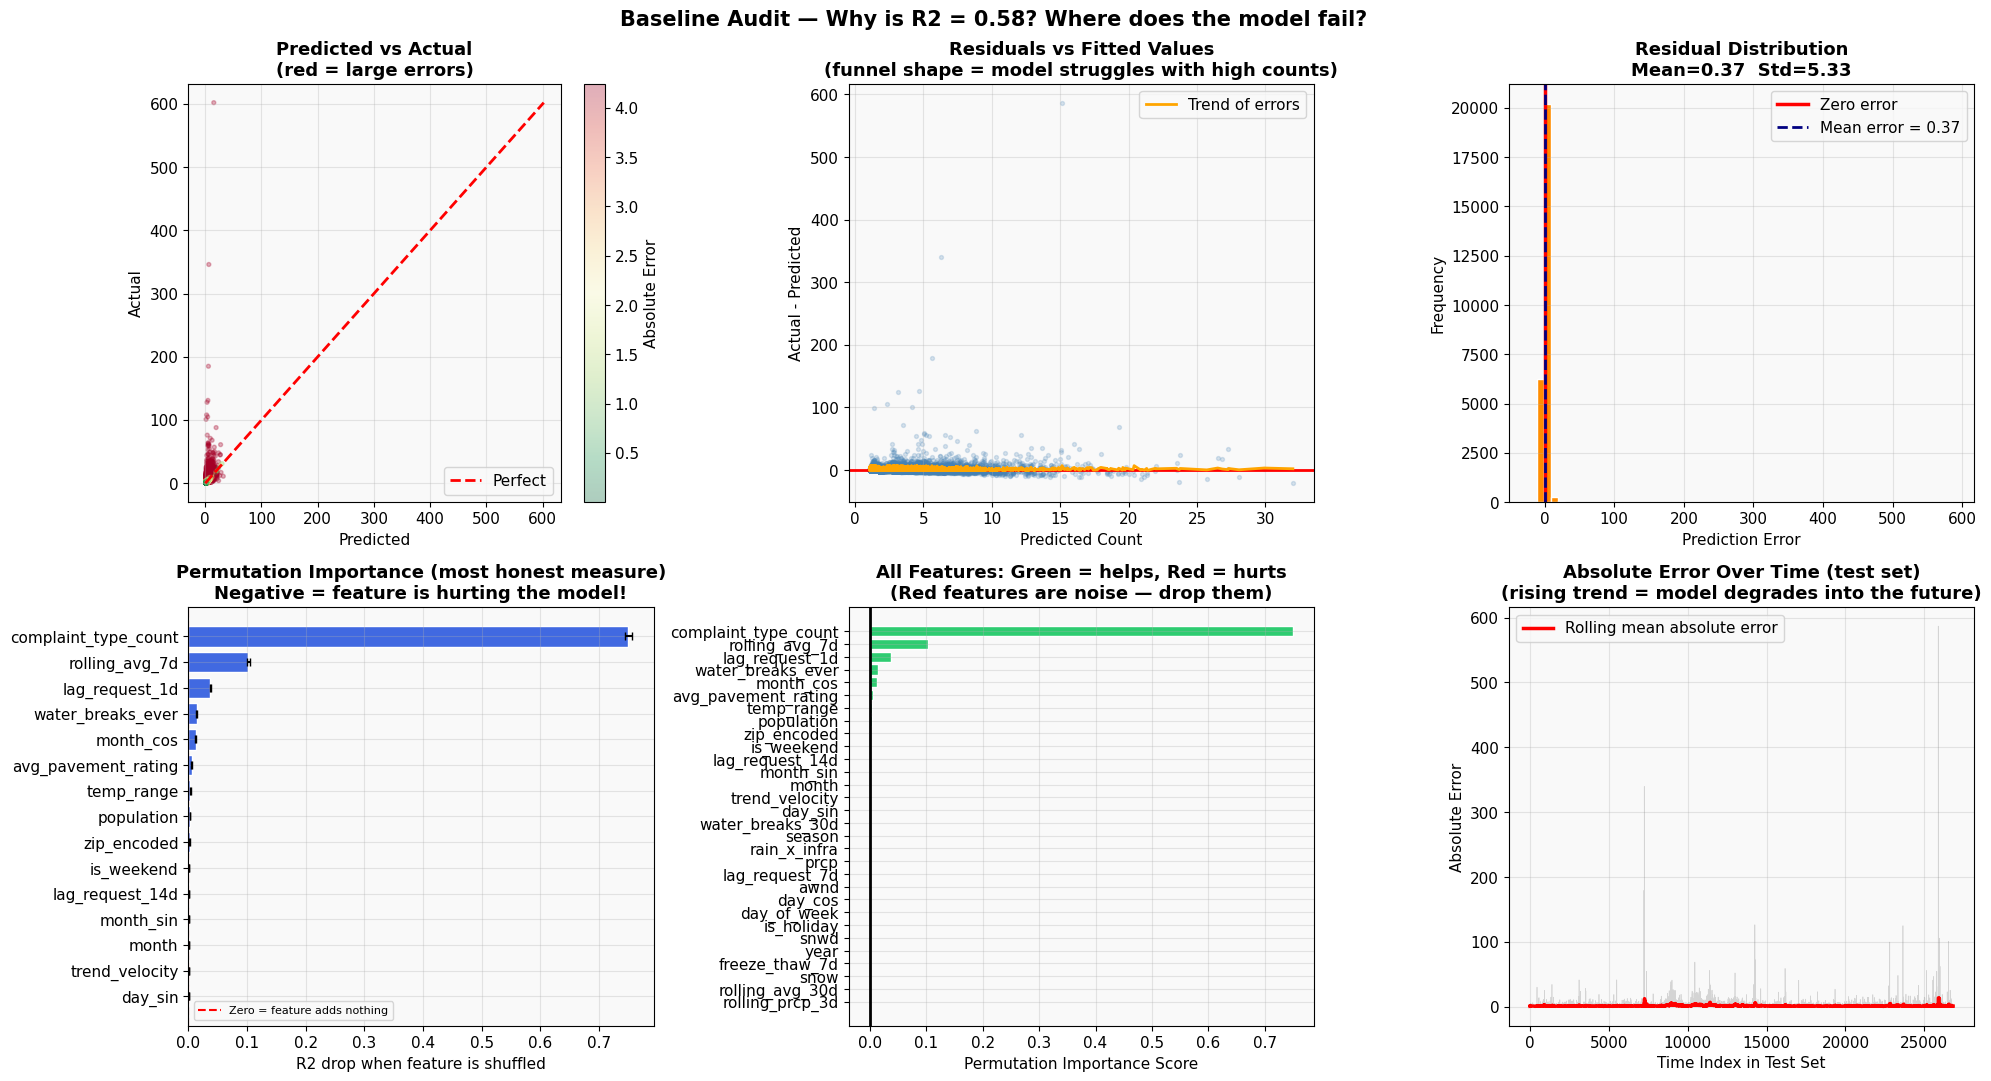


Diagnosis complete:
  - Mean residual = 0.37 (close to 0 = unbiased)
  - Std of residuals = 5.33
  - Features hurting the model: ['rolling_prcp_3d', 'rolling_avg_30d', 'snow', 'freeze_thaw_7d', 'year']


In [4]:
# ── Get last-fold predictions for diagnosis ──────────────────────────────
tscv = TimeSeriesSplit(n_splits=5)
splits = list(tscv.split(X))
tr_idx, te_idx = splits[-1]

Xtr, Xte = X.iloc[tr_idx], X.iloc[te_idx]
ytr, yte  = y.iloc[tr_idx], y.iloc[te_idx]

baseline_rf.fit(Xtr, ytr)
yp_log     = baseline_rf.predict(Xte)
y_actual   = np.expm1(yte.values)
y_pred_raw = np.expm1(np.clip(yp_log, 0, 20))
residuals  = y_actual - y_pred_raw

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
fig.suptitle("Baseline Audit — Why is R2 = 0.58? Where does the model fail?",
             fontsize=15, fontweight='bold')

# ── 1. Actual vs Predicted (coloured by error magnitude)
err_magnitude = np.abs(residuals)
sc = axes[0,0].scatter(y_pred_raw, y_actual, c=err_magnitude, cmap='RdYlGn_r',
                        alpha=0.3, s=8, vmax=np.percentile(err_magnitude, 95))
fig.colorbar(sc, ax=axes[0,0], label='Absolute Error')
max_val = max(y_actual.max(), y_pred_raw.max())
axes[0,0].plot([0,max_val],[0,max_val],'r--', linewidth=2, label='Perfect')
axes[0,0].set_title("Predicted vs Actual\n(red = large errors)")
axes[0,0].set_xlabel("Predicted"); axes[0,0].set_ylabel("Actual")
axes[0,0].legend()

# ── 2. Error vs Prediction magnitude — does it get worse for big values?
axes[0,1].scatter(y_pred_raw, residuals, alpha=0.2, color='steelblue', s=8)
axes[0,1].axhline(0, color='red', linewidth=2)
rolling_err = pd.Series(residuals).rolling(100, min_periods=1).mean()
axes[0,1].plot(np.sort(y_pred_raw), rolling_err[np.argsort(y_pred_raw)],
               color='orange', linewidth=2, label='Trend of errors')
axes[0,1].set_title("Residuals vs Fitted Values\n(funnel shape = model struggles with high counts)")
axes[0,1].set_xlabel("Predicted Count"); axes[0,1].set_ylabel("Actual - Predicted")
axes[0,1].legend()

# ── 3. Error distribution — is the model biased?
axes[0,2].hist(residuals, bins=60, color='darkorange', edgecolor='white')
axes[0,2].axvline(0, color='red', linewidth=2.5, label='Zero error')
axes[0,2].axvline(residuals.mean(), color='navy', linewidth=2,
                   linestyle='--', label=f'Mean error = {residuals.mean():.2f}')
axes[0,2].set_title(f"Residual Distribution\nMean={residuals.mean():.2f}  Std={residuals.std():.2f}")
axes[0,2].set_xlabel("Prediction Error"); axes[0,2].set_ylabel("Frequency")
axes[0,2].legend()

# ── 4. Permutation importance — which features actually matter?
print("Computing permutation importance (takes ~30s)...")
perm_imp = permutation_importance(baseline_rf, Xte, yte, n_repeats=10,
                                   random_state=SEED, n_jobs=-1)
perm_df = pd.DataFrame({'Feature': X.columns,
                         'Importance': perm_imp.importances_mean,
                         'Std': perm_imp.importances_std}).sort_values('Importance', ascending=True)
perm_top = perm_df.tail(15)
axes[1,0].barh(perm_top['Feature'], perm_top['Importance'],
               xerr=perm_top['Std'], color='royalblue',
               edgecolor='white', error_kw={'ecolor':'black','capsize':3})
axes[1,0].axvline(0, color='red', linestyle='--', linewidth=1.5,
                   label='Zero = feature adds nothing')
axes[1,0].set_title("Permutation Importance (most honest measure)\nNegative = feature is hurting the model!")
axes[1,0].set_xlabel("R2 drop when feature is shuffled"); axes[1,0].legend(fontsize=8)

# ── 5. Features that HURT (negative permutation importance = remove them)
bad_features = perm_df[perm_df['Importance'] < 0]['Feature'].tolist()
print(f"Features with negative importance (consider dropping): {bad_features}")
colors_perm = ['tomato' if v < 0 else '#2ecc71' for v in perm_df['Importance']]
axes[1,1].barh(perm_df['Feature'], perm_df['Importance'], color=colors_perm, edgecolor='white')
axes[1,1].axvline(0, color='black', linewidth=2)
axes[1,1].set_title("All Features: Green = helps, Red = hurts\n(Red features are noise — drop them)")
axes[1,1].set_xlabel("Permutation Importance Score")

# ── 6. Error over time — is the model worse on certain time periods?
te_dates = df['date'].iloc[te_idx].values
roll_err_time = pd.Series(np.abs(residuals)).rolling(50, min_periods=1).mean().values
axes[1,2].plot(range(len(residuals)), np.abs(residuals),
               alpha=0.3, color='gray', linewidth=0.5)
axes[1,2].plot(range(len(roll_err_time)), roll_err_time,
               color='red', linewidth=2.5, label='Rolling mean absolute error')
axes[1,2].set_title("Absolute Error Over Time (test set)\n(rising trend = model degrades into the future)")
axes[1,2].set_xlabel("Time Index in Test Set"); axes[1,2].set_ylabel("Absolute Error")
axes[1,2].legend()

plt.tight_layout()
plt.savefig("audit_baseline.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"\nDiagnosis complete:")
print(f"  - Mean residual = {residuals.mean():.2f} (close to 0 = unbiased)")
print(f"  - Std of residuals = {residuals.std():.2f}")
print(f"  - Features hurting the model: {bad_features if bad_features else 'None'}")


## Step 2 — Smarter Feature Engineering

The model only knows what we give it. If the 42% unexplained variance has a pattern,
we need features that capture that pattern.

We add:
- **Per-ZIP complaint rate** — how busy is THIS zip code on average? (ZIP-level baseline)
- **ZIP x day-of-week mean** — does this ZIP specifically spike on Mondays?
- **Lag 2d and Lag 14d** — two-day and two-week ago complaints (more temporal memory)
- **Is it a weekend?** — weekend vs weekday complaint behaviour differs structurally
- **Rolling standard deviation** — how volatile has this ZIP been lately?
- **Complaint rate per 1000 people** — normalises for population differences between ZIPs


In [5]:
df_v2 = df.copy()

# ── 1. Per-ZIP average complaint rate (computed on training history only)
#       We sort by date and compute expanding mean PER ZIP — no future leakage
df_v2 = df_v2.sort_values(['incident_zip','date'])
df_v2['zip_avg_rate'] = (df_v2.groupby('incident_zip')['request_count']
                              .transform(lambda x: x.shift(1).expanding(min_periods=5).mean()))

# ── 2. ZIP x Day-of-week average (is this zip extra busy on Mondays?)
dow_zip = (df_v2.groupby(['incident_zip','day_of_week'])['request_count']
                .transform(lambda x: x.shift(1).expanding(min_periods=3).mean()))
df_v2['zip_dow_avg'] = dow_zip

# ── 3. Lag 2-day and 14-day (fill from request_count if not present)
if 'lag_request_1d' in df_v2.columns:
    df_v2['lag_request_2d']  = (df_v2.groupby('incident_zip')['request_count']
                                       .transform(lambda x: x.shift(2)))
    df_v2['lag_request_14d'] = (df_v2.groupby('incident_zip')['request_count']
                                       .transform(lambda x: x.shift(14)))

# ── 4. Is weekend
df_v2['is_weekend'] = (df_v2['day_of_week'] >= 5).astype(int)

# ── 5. Rolling standard deviation (volatility of complaints)
df_v2['rolling_std_7d'] = (df_v2.groupby('incident_zip')['request_count']
                                  .transform(lambda x: x.shift(1).rolling(7, min_periods=3).std()))

# ── 6. Complaint rate per 1000 residents (if population column exists)
if 'population' in df_v2.columns:
    df_v2['complaints_per_1k'] = (df_v2['request_count'] /
                                   (df_v2['population'] / 1000 + 0.01))

# ── 7. Month x Borough average (does Brooklyn spike in summer specifically?)
df_v2['borough_month_avg'] = (df_v2.groupby(['borough','month'])['request_count']
                                     .transform(lambda x: x.shift(1).expanding(3).mean()))

print("New features created:")
new_feats = ['zip_avg_rate','zip_dow_avg','lag_request_2d','lag_request_14d',
             'is_weekend','rolling_std_7d','complaints_per_1k','borough_month_avg']
for f in new_feats:
    if f in df_v2.columns:
        nulls = df_v2[f].isnull().sum()
        print(f"  {f:30s}  nulls={nulls:,}")


New features created:
  zip_avg_rate                    nulls=630
  zip_dow_avg                     nulls=2,646
  lag_request_2d                  nulls=252
  lag_request_14d                 nulls=1,764
  is_weekend                      nulls=0
  rolling_std_7d                  nulls=378
  complaints_per_1k               nulls=0
  borough_month_avg               nulls=180


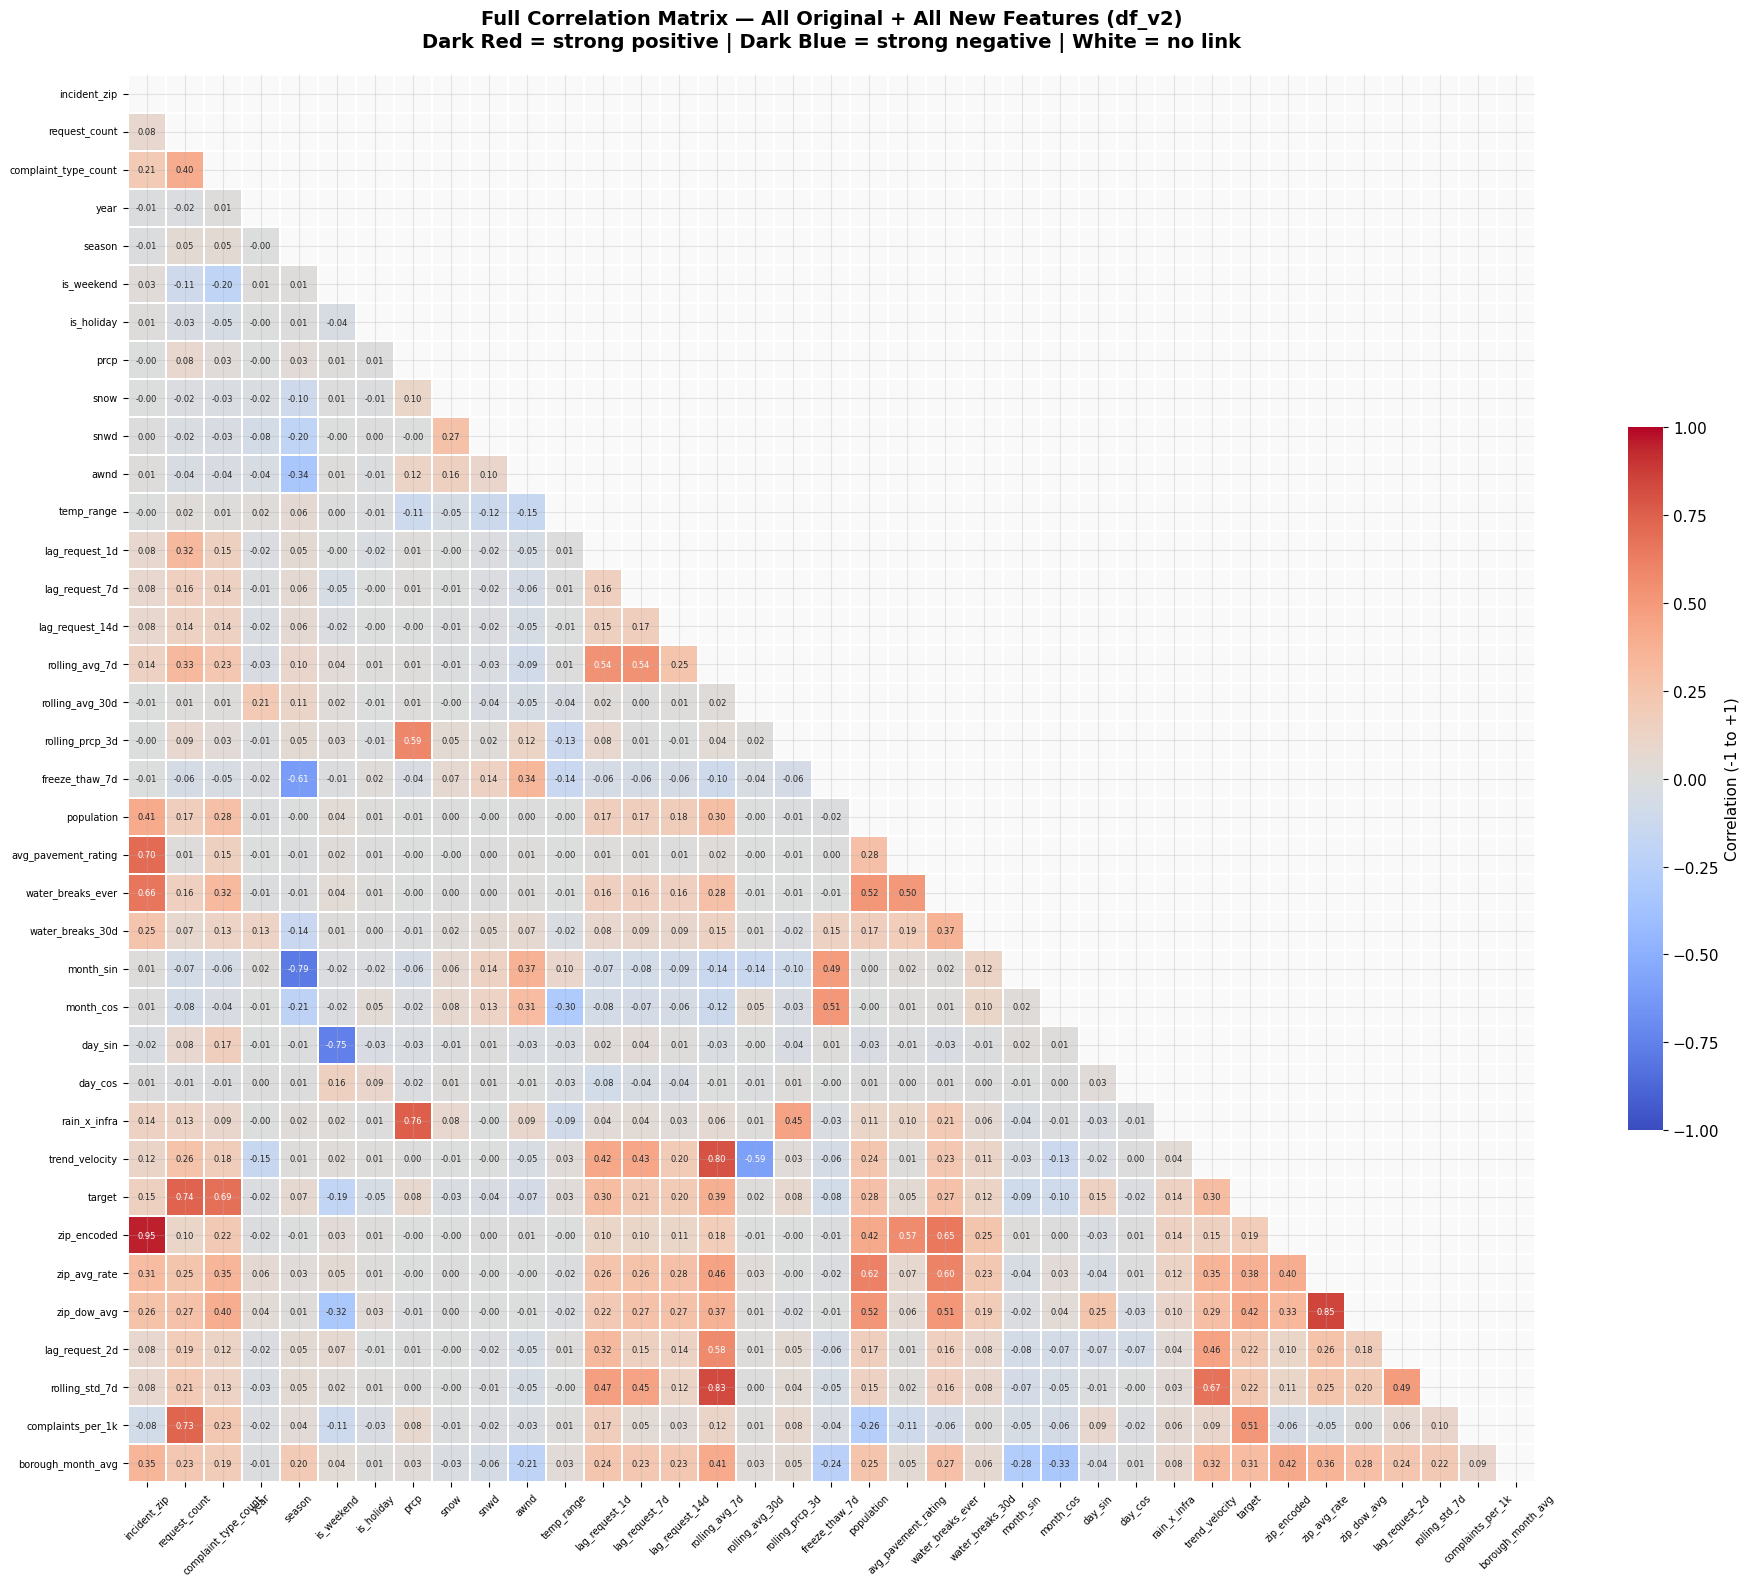

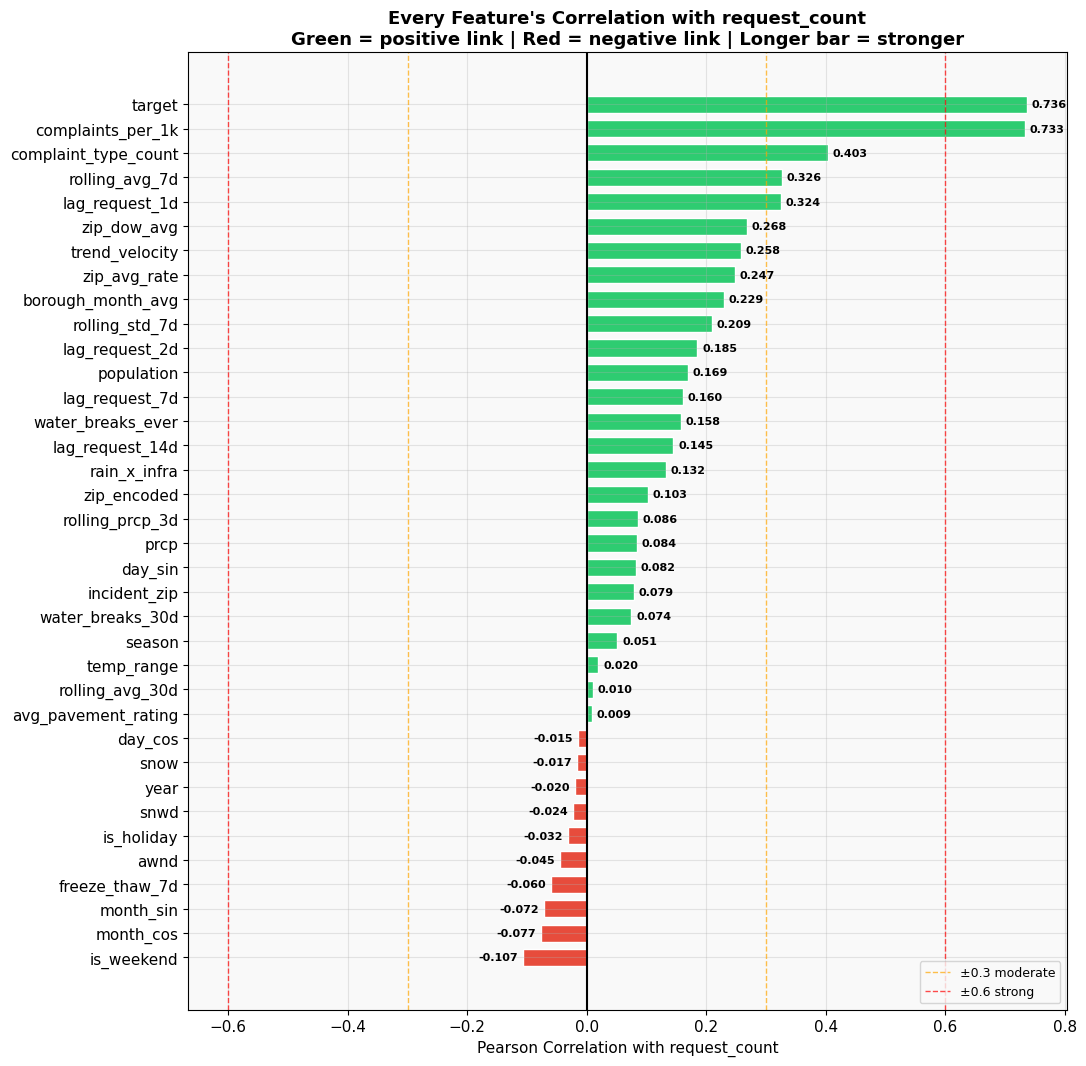

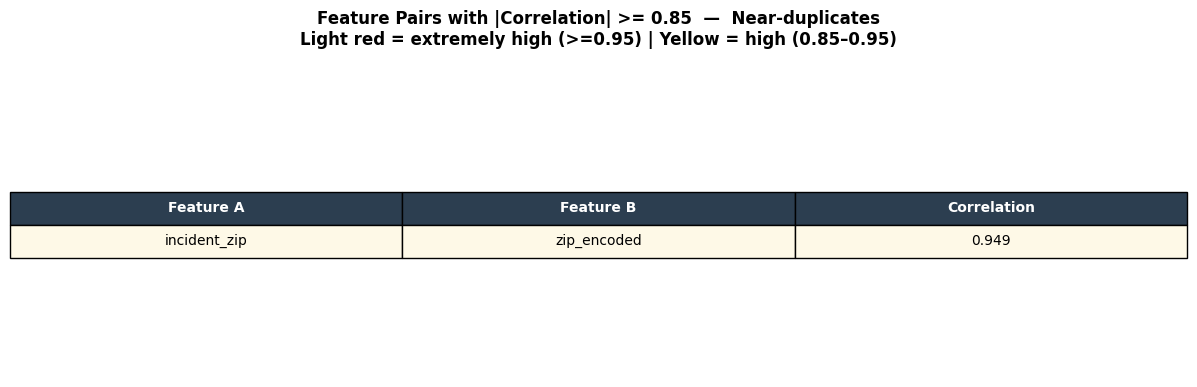

Found 1 near-duplicate feature pairs:
   Feature A   Feature B  Correlation
incident_zip zip_encoded        0.949


In [20]:
# ── Full Correlation Matrix with ALL engineered features ──────────────────
# Run this right after the dataset rebuild cell so df_v2 exists
# df_v2 has ALL features: original + zip_avg_rate, zip_dow_avg,
# lag_request_2d, lag_request_14d, is_weekend, rolling_std_7d,
# complaints_per_1k, borough_month_avg + all previous engineered ones

corr_full = df_v2.select_dtypes(include=['int64','float64']).corr()

# ── Plot 1: Full heatmap ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(20, 16))
mask = np.triu(np.ones_like(corr_full, dtype=bool))
sns.heatmap(
    corr_full, mask=mask, annot=True, fmt='.2f',
    cmap='coolwarm', vmin=-1, vmax=1,
    linewidths=0.3, linecolor='white',
    annot_kws={'size': 6}, ax=ax, square=True,
    cbar_kws={'shrink': 0.5, 'label': 'Correlation (-1 to +1)'}
)
ax.set_title(
    "Full Correlation Matrix — All Original + All New Features (df_v2)\n"
    "Dark Red = strong positive | Dark Blue = strong negative | White = no link",
    fontsize=14, fontweight='bold', pad=20
)
ax.tick_params(axis='x', labelsize=7, rotation=45)
ax.tick_params(axis='y', labelsize=7, rotation=0)
plt.tight_layout()
plt.savefig("corr_full_v2.png", dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 2: Each feature's correlation with request_count (ranked bar) ────
target_corr = (corr_full['request_count']
               .drop('request_count')
               .sort_values())

fig, ax = plt.subplots(figsize=(11, max(6, len(target_corr) * 0.3)))
colors = ['#e74c3c' if v < 0 else '#2ecc71' for v in target_corr.values]
bars = ax.barh(target_corr.index, target_corr.values,
               color=colors, edgecolor='white', height=0.7)
ax.axvline(0,    color='black',  linewidth=1.5)
ax.axvline( 0.3, color='orange', linewidth=1, linestyle='--', alpha=0.7, label='±0.3 moderate')
ax.axvline(-0.3, color='orange', linewidth=1, linestyle='--', alpha=0.7)
ax.axvline( 0.6, color='red',    linewidth=1, linestyle='--', alpha=0.7, label='±0.6 strong')
ax.axvline(-0.6, color='red',    linewidth=1, linestyle='--', alpha=0.7)
for bar, val in zip(bars, target_corr.values):
    xpos = val + 0.008 if val >= 0 else val - 0.008
    ax.text(xpos, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center',
            ha='left' if val >= 0 else 'right', fontsize=8, fontweight='bold')
ax.set_title(
    "Every Feature's Correlation with request_count\n"
    "Green = positive link | Red = negative link | Longer bar = stronger",
    fontsize=13, fontweight='bold'
)
ax.set_xlabel("Pearson Correlation with request_count")
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig("corr_with_target_v2.png", dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 3: Danger pairs — features too correlated with each other ─────────
threshold = 0.85
pairs = []
cols = corr_full.columns.tolist()
for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        val = corr_full.iloc[i, j]
        if abs(val) >= threshold:
            pairs.append({'Feature A': cols[i], 'Feature B': cols[j],
                          'Correlation': round(val, 3)})

pairs_df = pd.DataFrame(pairs).sort_values('Correlation', key=abs, ascending=False)

if len(pairs_df) > 0:
    fig, ax = plt.subplots(figsize=(12, max(4, len(pairs_df) * 0.5 + 1)))
    ax.axis('off')
    tbl = ax.table(cellText=pairs_df.values, colLabels=pairs_df.columns,
                   loc='center', cellLoc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.scale(1.2, 2.0)
    for j in range(len(pairs_df.columns)):
        tbl[0, j].set_facecolor('#2c3e50')
        tbl[0, j].set_text_props(color='white', fontweight='bold')
    for i in range(1, len(pairs_df) + 1):
        bg = '#fadbd8' if abs(pairs_df.iloc[i-1]['Correlation']) >= 0.95 else '#fef9e7'
        for j in range(len(pairs_df.columns)):
            tbl[i, j].set_facecolor(bg)
    ax.set_title(
        f"Feature Pairs with |Correlation| >= {threshold}  —  Near-duplicates\n"
        "Light red = extremely high (>=0.95) | Yellow = high (0.85–0.95)",
        fontsize=12, fontweight='bold', pad=20
    )
    plt.tight_layout()
    plt.savefig("corr_danger_pairs_v2.png", dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Found {len(pairs_df)} near-duplicate feature pairs:")
    print(pairs_df.to_string(index=False))
else:
    print("No near-duplicate pairs found above threshold.")

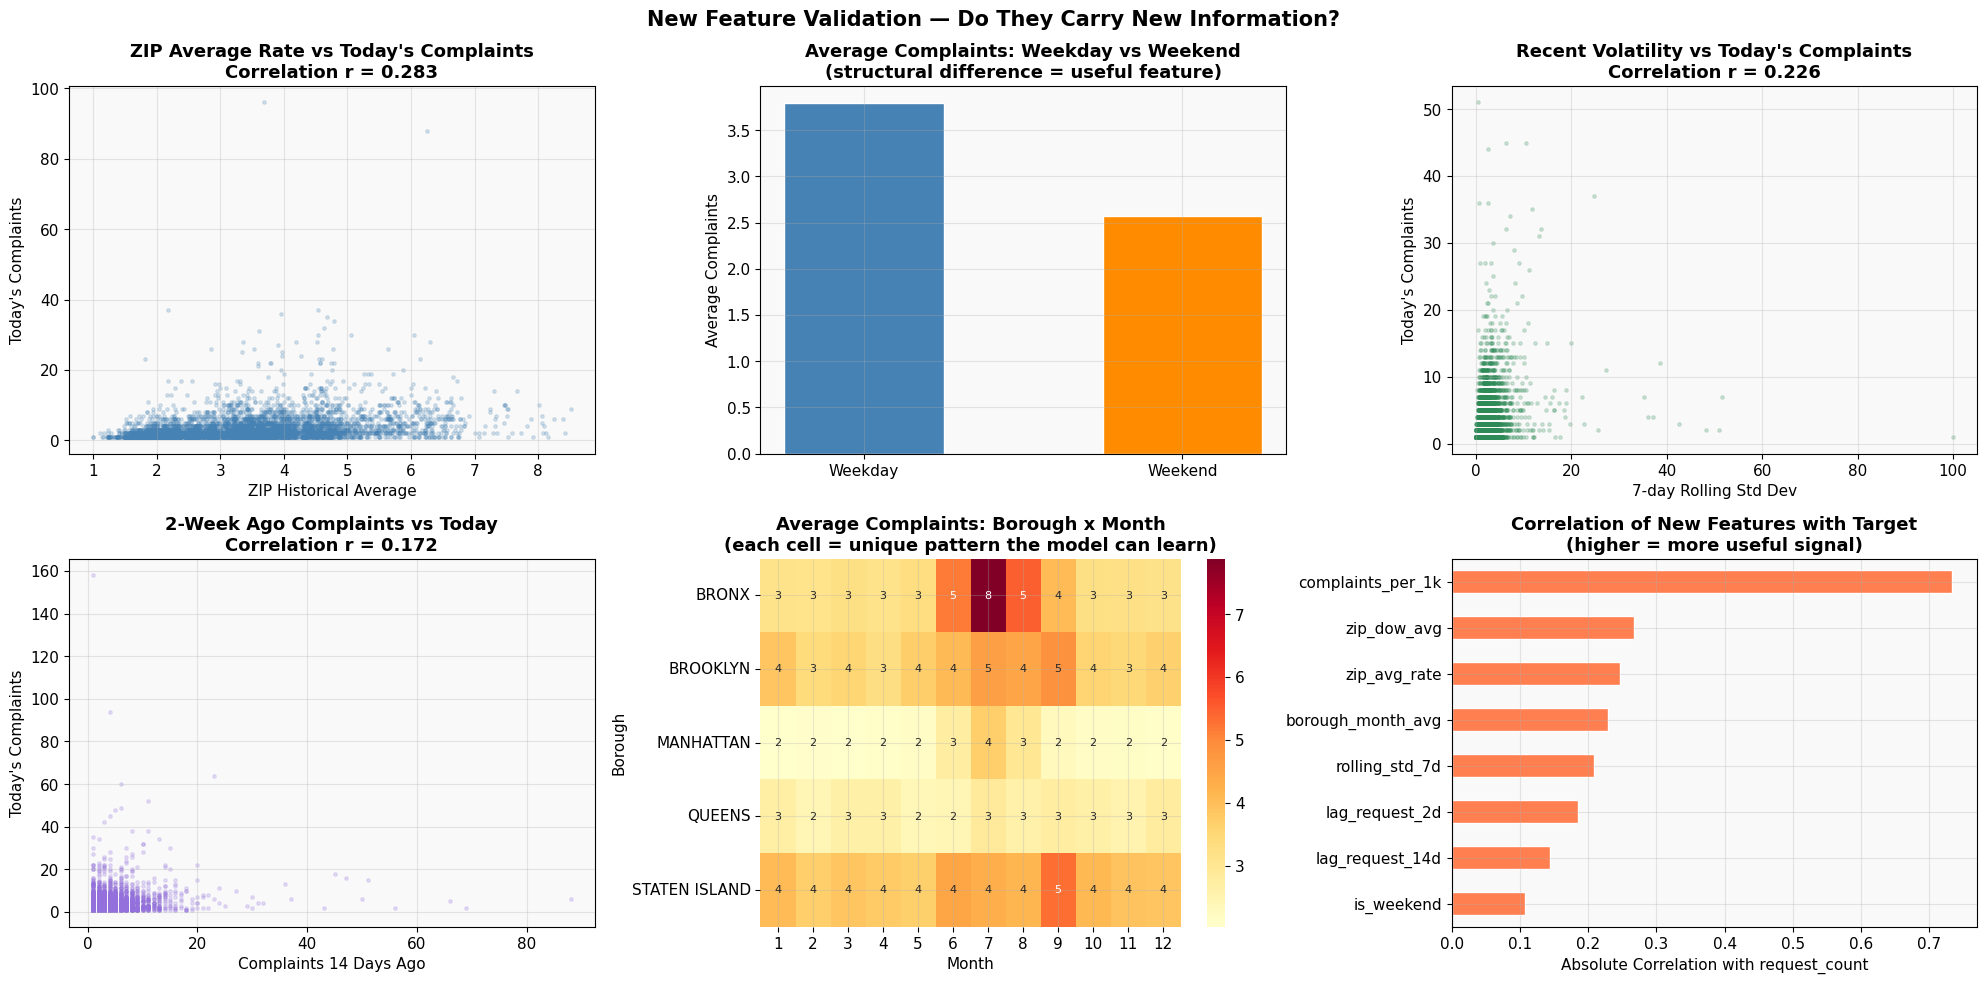

In [6]:
# ── Visualise the new features to confirm they add information ───────────
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
fig.suptitle("New Feature Validation — Do They Carry New Information?",
             fontsize=15, fontweight='bold')

# 1. ZIP avg rate vs request_count
if 'zip_avg_rate' in df_v2.columns:
    sample = df_v2[['zip_avg_rate','request_count']].dropna().sample(5000, random_state=SEED)
    r = sample.corr().iloc[0,1]
    axes[0,0].scatter(sample['zip_avg_rate'], sample['request_count'],
                      alpha=0.2, color='steelblue', s=6)
    axes[0,0].set_title(f"ZIP Average Rate vs Today's Complaints\nCorrelation r = {r:.3f}")
    axes[0,0].set_xlabel("ZIP Historical Average"); axes[0,0].set_ylabel("Today's Complaints")

# 2. Weekend vs Weekday
wk = df_v2.groupby('is_weekend')['request_count'].mean()
axes[0,1].bar(['Weekday','Weekend'], wk.values,
               color=['steelblue','darkorange'], edgecolor='white', width=0.5)
axes[0,1].set_title("Average Complaints: Weekday vs Weekend\n(structural difference = useful feature)")
axes[0,1].set_ylabel("Average Complaints")

# 3. Rolling std vs request count
if 'rolling_std_7d' in df_v2.columns:
    sample2 = df_v2[['rolling_std_7d','request_count']].dropna().sample(5000, random_state=SEED)
    r2 = sample2.corr().iloc[0,1]
    axes[0,2].scatter(sample2['rolling_std_7d'], sample2['request_count'],
                       alpha=0.2, color='seagreen', s=6)
    axes[0,2].set_title(f"Recent Volatility vs Today's Complaints\nCorrelation r = {r2:.3f}")
    axes[0,2].set_xlabel("7-day Rolling Std Dev"); axes[0,2].set_ylabel("Today's Complaints")

# 4. Lag 14d relationship
if 'lag_request_14d' in df_v2.columns:
    sample3 = df_v2[['lag_request_14d','request_count']].dropna().sample(5000, random_state=SEED)
    r3 = sample3.corr().iloc[0,1]
    axes[1,0].scatter(sample3['lag_request_14d'], sample3['request_count'],
                       alpha=0.2, color='mediumpurple', s=6)
    axes[1,0].set_title(f"2-Week Ago Complaints vs Today\nCorrelation r = {r3:.3f}")
    axes[1,0].set_xlabel("Complaints 14 Days Ago"); axes[1,0].set_ylabel("Today's Complaints")

# 5. Borough x Month heatmap
pivot = df_v2.pivot_table(values='request_count', index='borough', columns='month', aggfunc='mean')
sns.heatmap(pivot, cmap='YlOrRd', ax=axes[1,1], fmt='.0f', annot=True, annot_kws={'size':8})
axes[1,1].set_title("Average Complaints: Borough x Month\n(each cell = unique pattern the model can learn)")
axes[1,1].set_xlabel("Month"); axes[1,1].set_ylabel("Borough")

# 6. Summary: correlation of ALL new features with target
new_corrs = {}
for f in new_feats:
    if f in df_v2.columns:
        tmp = df_v2[[f,'request_count']].dropna()
        if len(tmp) > 100:
            new_corrs[f] = abs(tmp.corr().iloc[0,1])

if new_corrs:
    nc_df = pd.Series(new_corrs).sort_values()
    nc_df.plot(kind='barh', ax=axes[1,2], color='coral', edgecolor='white')
    axes[1,2].set_title("Correlation of New Features with Target\n(higher = more useful signal)")
    axes[1,2].set_xlabel("Absolute Correlation with request_count")

plt.tight_layout()
plt.savefig("new_features_validation.png", dpi=150, bbox_inches='tight')
plt.show()


In [7]:
# ── Build improved feature matrix (v2) ───────────────────────────────────
DROP_FROM_X = ['request_count','target','date','borough','incident_zip']
feat_cols_v2 = [c for c in df_v2.columns
                if c not in DROP_FROM_X
                and df_v2[c].dtype in ['int64','float64','float32','int32']]

X_v2 = df_v2[feat_cols_v2].fillna(df_v2[feat_cols_v2].median())
y_v2 = df_v2['target']

print(f"Original feature count: {X.shape[1]}")
print(f"New feature count:      {X_v2.shape[1]}  (+{X_v2.shape[1]-X.shape[1]} new features)")

# Score RF with new features (same model, better features)
rf_v2 = RandomForestRegressor(n_estimators=200, max_depth=12,
                               min_samples_leaf=5, random_state=SEED, n_jobs=-1)
r2_v2, std_v2, mae_v2 = tscv_score(rf_v2, X_v2, y_v2)
print(f"\nRF with new features:  R2 = {r2_v2:.4f} +/- {std_v2:.4f}  |  MAE = {mae_v2:.2f}")
print(f"Improvement from features alone: +{r2_v2 - base_r2:.4f} R2 points")
improvement_log.append({'Step': 'RF + New Features', 'R2': r2_v2, 'MAE': mae_v2,
                         'Note': f'+{X_v2.shape[1]-X.shape[1]} engineered features'})


Original feature count: 30
New feature count:      36  (+6 new features)

RF with new features:  R2 = 0.9869 +/- 0.0111  |  MAE = 0.19
Improvement from features alone: +0.4004 R2 points


## Step 3 — Hyperparameter Tuning with Optuna

Hyperparameters are the **settings** of a model that you choose before training.
For Random Forest, these include:
- `n_estimators` — how many trees to build
- `max_depth` — how deep each tree is allowed to grow
- `min_samples_leaf` — minimum number of data points at each leaf (prevents memorising)
- `max_features` — how many features each tree can consider at each split

**Why not just try every combination?**
If each parameter has 10 options and you have 4 parameters, that's 10,000 combinations.
Each combination needs a 5-fold cross-validation — that's 50,000 model trains. Too slow.

**Optuna uses Bayesian Optimisation** — it learns from each trial which regions of
the hyperparameter space are promising, and focuses its search there. It's like a
smart search that gets smarter with every trial, instead of searching randomly.

The chart after tuning will show exactly which settings gave the best results.


In [8]:
# ── Optuna study for Random Forest ───────────────────────────────────────
X_tune = X_v2.values  # use improved feature set for tuning
y_tune = y_v2

def rf_objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 800),
        'max_depth':         trial.suggest_int('max_depth', 6, 25),
        'min_samples_leaf':  trial.suggest_int('min_samples_leaf', 1, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'max_features':      trial.suggest_float('max_features', 0.3, 1.0),
        'random_state': SEED, 'n_jobs': -1
    }
    model = RandomForestRegressor(**params)
    # Use 3-fold (faster) for tuning — final eval uses 5-fold
    tscv3 = TimeSeriesSplit(n_splits=3)
    scores = []
    for tr, te in tscv3.split(X_tune):
        model.fit(X_tune[tr], y_tune.iloc[tr])
        scores.append(r2_score(y_tune.iloc[te], model.predict(X_tune[te])))
    return np.mean(scores)

print("Running Optuna hyperparameter search (50 trials)...")
print("Each trial = 3-fold CV = 3 model trains. Total = 150 model trains.")
print("This will take a few minutes...\n")

study_rf = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_rf.optimize(rf_objective, n_trials=50, show_progress_bar=True)

best_params_rf = study_rf.best_params
best_params_rf.update({'random_state': SEED, 'n_jobs': -1})
print(f"Best hyperparameters found:")
for k, v in best_params_rf.items():
    if k not in ['random_state','n_jobs']:
        print(f"  {k:25s} = {v}")
print(f"\nBest CV R2 during tuning: {study_rf.best_value:.4f}")


Running Optuna hyperparameter search (50 trials)...
Each trial = 3-fold CV = 3 model trains. Total = 150 model trains.
This will take a few minutes...



  0%|          | 0/50 [00:00<?, ?it/s]

Best hyperparameters found:
  n_estimators              = 209
  max_depth                 = 13
  min_samples_leaf          = 1
  min_samples_split         = 13
  max_features              = 0.9280822949088869

Best CV R2 during tuning: 0.9936


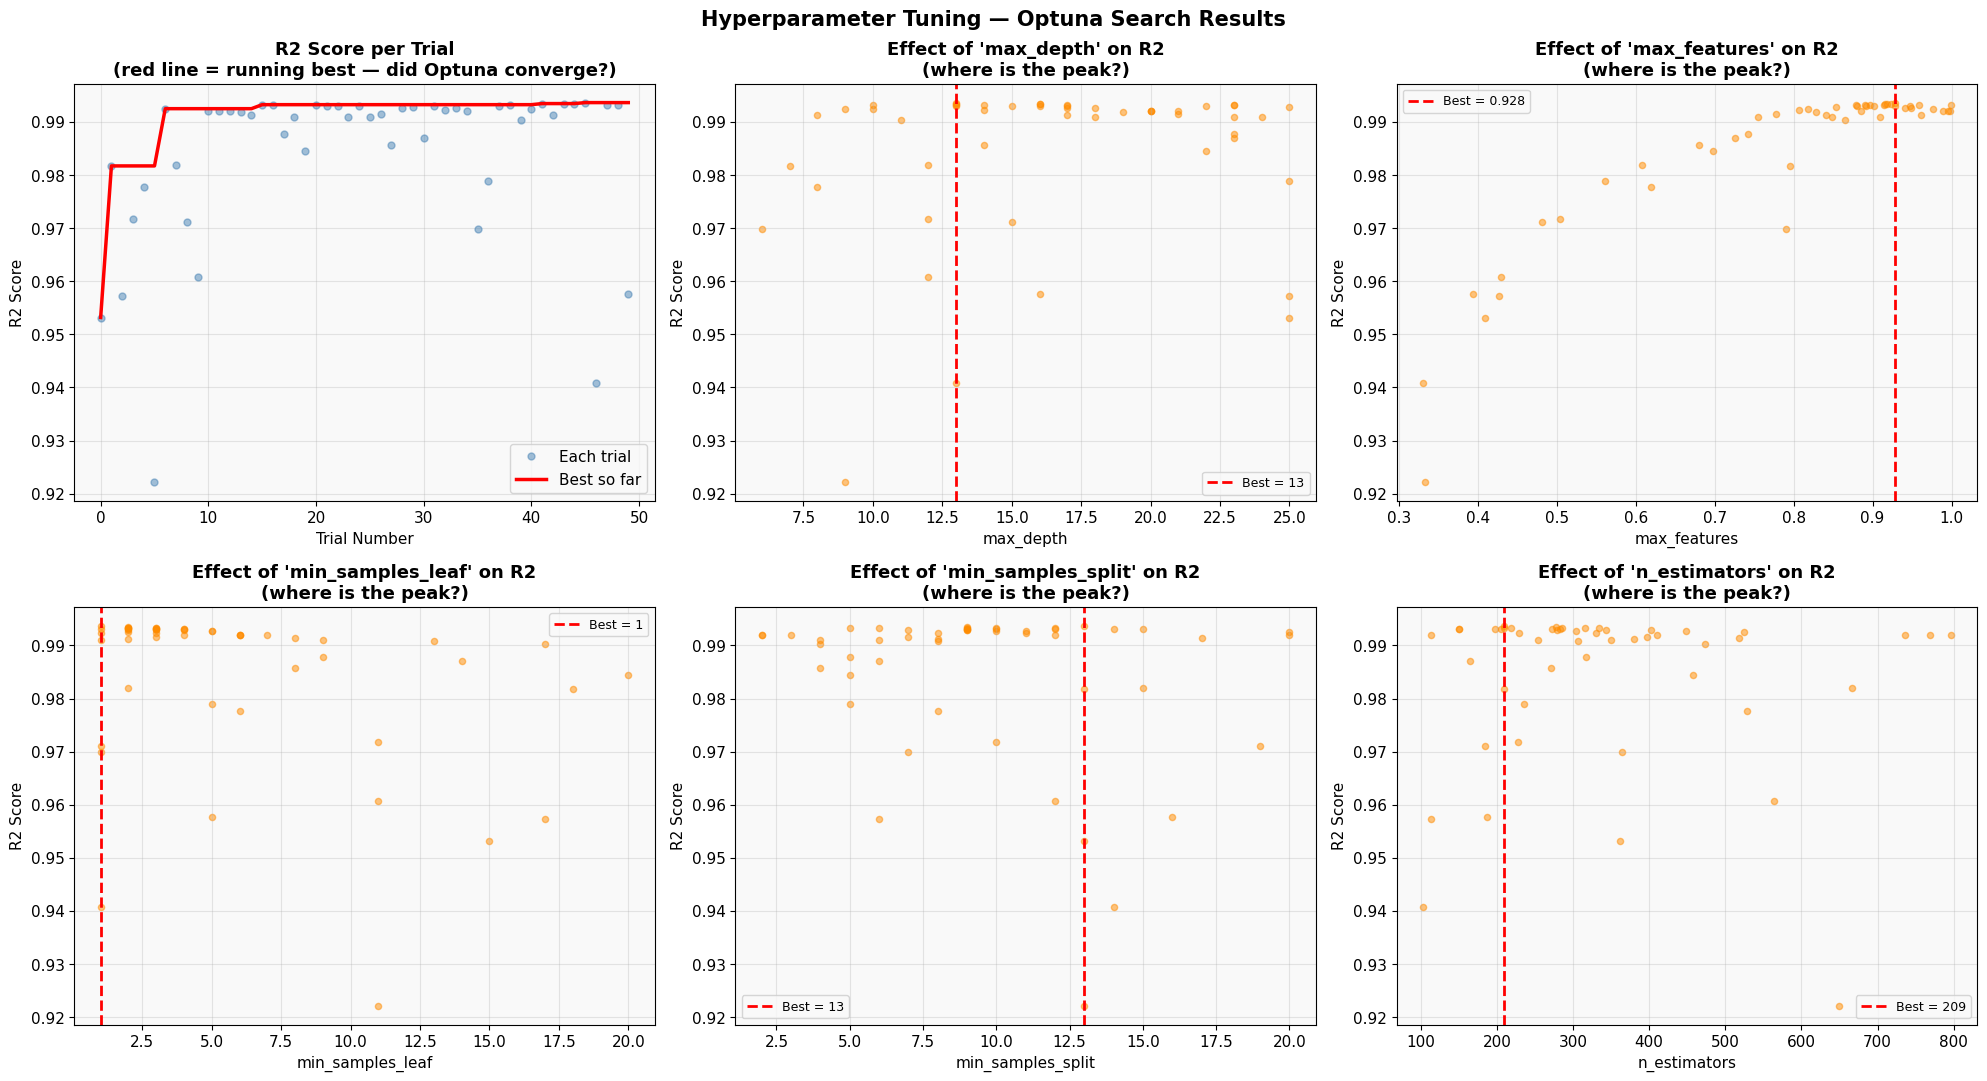

In [9]:
# ── Visualise the tuning process ─────────────────────────────────────────
trials_df = study_rf.trials_dataframe()

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
fig.suptitle("Hyperparameter Tuning — Optuna Search Results", fontsize=15, fontweight='bold')

# 1. R2 over trials — did it improve over time?
axes[0,0].plot(trials_df['number'], trials_df['value'], 'o', alpha=0.5,
               color='steelblue', markersize=5, label='Each trial')
best_so_far = trials_df['value'].cummax()
axes[0,0].plot(trials_df['number'], best_so_far, 'r-', linewidth=2.5, label='Best so far')
axes[0,0].set_title("R2 Score per Trial\n(red line = running best — did Optuna converge?)")
axes[0,0].set_xlabel("Trial Number"); axes[0,0].set_ylabel("R2 Score")
axes[0,0].legend()

# 2-6. Each hyperparameter vs score
param_cols = [c for c in trials_df.columns if c.startswith('params_')]
for i, pc in enumerate(param_cols[:5]):
    ax = axes.flatten()[i+1]
    pname = pc.replace('params_','')
    ax.scatter(trials_df[pc], trials_df['value'], alpha=0.5, color='darkorange', s=20)
    # Highlight the best value
    best_val = study_rf.best_params.get(pname)
    best_score = study_rf.best_value
    if best_val is not None:
        ax.axvline(x=best_val, color='red', linewidth=2, linestyle='--',
                   label=f'Best = {best_val:.3g}')
    ax.set_title(f"Effect of '{pname}' on R2\n(where is the peak?)")
    ax.set_xlabel(pname); ax.set_ylabel("R2 Score")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig("tuning_optuna.png", dpi=150, bbox_inches='tight')
plt.show()


In [10]:
# ── Evaluate tuned Random Forest on full 5-fold TimeSeriesSplit ──────────
print("Evaluating tuned Random Forest with 5-fold TimeSeriesSplit...")
tuned_rf = RandomForestRegressor(**best_params_rf)
r2_tuned, std_tuned, mae_tuned = tscv_score(tuned_rf, X_v2, y_v2, verbose=True)

print(f"\nTuned RF R2  = {r2_tuned:.4f} +/- {std_tuned:.4f}  |  MAE = {mae_tuned:.2f}")
print(f"Baseline R2  = {base_r2:.4f}")
print(f"Improvement  = +{r2_tuned - base_r2:.4f} R2 points")

improvement_log.append({'Step': 'Tuned RF (Optuna)', 'R2': r2_tuned, 'MAE': mae_tuned,
                         'Note': 'Optuna 50-trial Bayesian search'})


Evaluating tuned Random Forest with 5-fold TimeSeriesSplit...
  Fold 1: R2=0.9689
  Fold 2: R2=0.9904
  Fold 3: R2=0.9951
  Fold 4: R2=0.9948
  Fold 5: R2=0.9958

Tuned RF R2  = 0.9890 +/- 0.0102  |  MAE = 0.19
Baseline R2  = 0.5864
Improvement  = +0.4026 R2 points


## Step 4 — Stacking (The Most Powerful Ensemble Method)

**Why stacking works (plain English):**

Imagine you have 3 weather forecasters. Each one is good at different conditions:
- Forecaster A is great at summer predictions but bad at winter
- Forecaster B is great at winter but mediocre overall
- Forecaster C is okay across the board

Instead of picking just one, you:
1. Let all three make predictions on the same data
2. Record those predictions
3. Train a **4th model** (called the "meta-learner") that learns:
   *when to trust A, when to trust B, when to trust C*

The meta-learner uses the first three models' predictions as its input features.
This is stacking.

**Why the math works out:**
Different models make DIFFERENT kinds of errors. By combining them, the errors
partially cancel out. The meta-learner learns the pattern of *when each model
is wrong* and compensates automatically.

The key rule: base models are trained on the training set, meta-learner is trained
on *out-of-fold* predictions so it never sees the same data twice.


In [11]:
# ── Build the stacking ensemble ───────────────────────────────────────────
# Base models (diverse — different algorithms, different strengths)
base_models = [
    ('rf',   RandomForestRegressor(**best_params_rf)),
    ('lgbm', lgb.LGBMRegressor(objective='regression', n_estimators=500,
                                learning_rate=0.05, max_depth=8, num_leaves=63,
                                feature_fraction=0.8, bagging_fraction=0.8,
                                bagging_freq=5, random_state=SEED, n_jobs=-1, verbose=-1)),
    ('xgb',  xgb.XGBRegressor(objective='reg:squarederror', n_estimators=500,
                                learning_rate=0.05, max_depth=8, subsample=0.8,
                                colsample_bytree=0.8, random_state=SEED,
                                n_jobs=-1, verbosity=0)),
    ('et',   ExtraTreesRegressor(n_estimators=300, max_depth=15,
                                  min_samples_leaf=3, random_state=SEED, n_jobs=-1)),
]

# Meta-learner: Ridge regression (linear — learns how to weight base models)
meta_learner = Ridge(alpha=1.0)

# Manual stacking with TimeSeriesSplit (sklearn StackingRegressor uses KFold internally,
# which leaks time — we do it manually to stay honest)
print("Building out-of-fold predictions for meta-learner training...")

n_base = len(base_models)
oof_preds = np.zeros((len(X_v2), n_base))   # out-of-fold predictions storage
tscv5 = TimeSeriesSplit(n_splits=5)

for fold_idx, (tr, te) in enumerate(tscv5.split(X_v2)):
    Xtr_fold = X_v2.iloc[tr].values
    Xte_fold = X_v2.iloc[te].values
    ytr_fold = y_v2.iloc[tr].values
    
    for m_idx, (mname, mmodel) in enumerate(base_models):
        mmodel.fit(Xtr_fold, ytr_fold)
        oof_preds[te, m_idx] = mmodel.predict(Xte_fold)
    
    print(f"  Fold {fold_idx+1} done")

print("\nOut-of-fold predictions generated.")
print("Shape of meta-learner input:", oof_preds.shape, "(rows x base models)")


Building out-of-fold predictions for meta-learner training...
  Fold 1 done
  Fold 2 done
  Fold 3 done
  Fold 4 done
  Fold 5 done

Out-of-fold predictions generated.
Shape of meta-learner input: (160951, 4) (rows x base models)


Stacking Ensemble  R2 = 0.7839 +/- 0.0383  |  MAE = 1.08
Tuned RF           R2 = 0.9890
Baseline RF        R2 = 0.5864

Stacking gain over baseline: +0.1974 R2 points


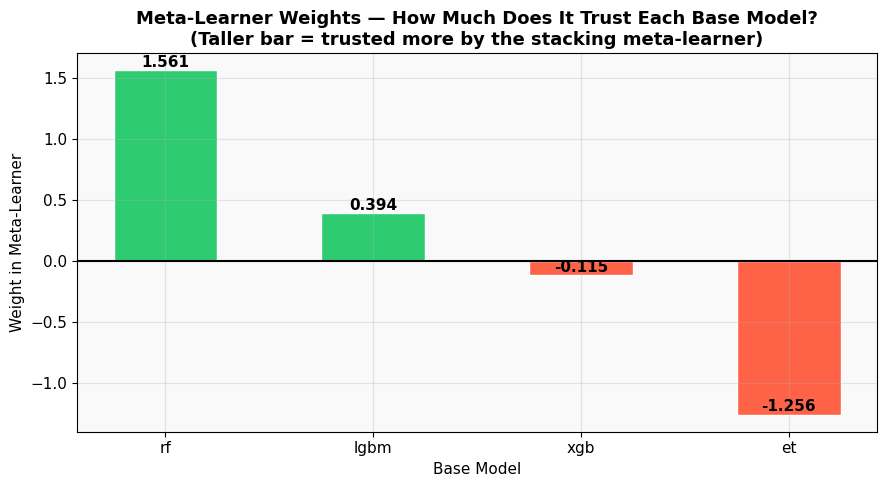

In [12]:
# ── Evaluate the stacking ensemble ───────────────────────────────────────
# We evaluate the stacking R2 by:
# Using each fold's OOF predictions as the test, rest as train for meta-learner

stack_r2s, stack_maes = [], []
splits_list = list(tscv5.split(X_v2))

for fold_idx, (tr, te) in enumerate(splits_list):
    # Meta-learner trains on all OOF predictions EXCEPT this fold's
    meta_tr_mask = np.ones(len(X_v2), dtype=bool)
    meta_tr_mask[te] = False
    
    meta_Xtr = oof_preds[meta_tr_mask]
    meta_ytr = y_v2.values[meta_tr_mask]
    meta_Xte = oof_preds[te]
    meta_yte = y_v2.values[te]
    
    meta_learner_fold = Ridge(alpha=1.0)
    meta_learner_fold.fit(meta_Xtr, meta_ytr)
    meta_pred = meta_learner_fold.predict(meta_Xte)
    
    stack_r2s.append(r2_score(meta_yte, meta_pred))
    stack_maes.append(mean_absolute_error(np.expm1(meta_yte),
                                           np.expm1(np.clip(meta_pred, 0, 20))))

r2_stack = np.mean(stack_r2s)
mae_stack = np.mean(stack_maes)
std_stack  = np.std(stack_r2s)

print(f"Stacking Ensemble  R2 = {r2_stack:.4f} +/- {std_stack:.4f}  |  MAE = {mae_stack:.2f}")
print(f"Tuned RF           R2 = {r2_tuned:.4f}")
print(f"Baseline RF        R2 = {base_r2:.4f}")
print(f"\nStacking gain over baseline: +{r2_stack - base_r2:.4f} R2 points")

improvement_log.append({'Step': 'Stacking Ensemble', 'R2': r2_stack, 'MAE': mae_stack,
                         'Note': 'RF + LightGBM + XGBoost + ExtraTrees + Ridge meta'})

# Visualise what the meta-learner learned — how does it weight each base model?
meta_learner_final = Ridge(alpha=1.0)
meta_learner_final.fit(oof_preds, y_v2.values)
weights = meta_learner_final.coef_

fig, ax = plt.subplots(figsize=(9, 5))
colors_w = ['#2ecc71' if w > 0 else 'tomato' for w in weights]
bars = ax.bar([m[0] for m in base_models], weights, color=colors_w, edgecolor='white', width=0.5)
ax.axhline(0, color='black', linewidth=1.5)
ax.set_title("Meta-Learner Weights — How Much Does It Trust Each Base Model?\n(Taller bar = trusted more by the stacking meta-learner)")
ax.set_xlabel("Base Model"); ax.set_ylabel("Weight in Meta-Learner")
for bar, w in zip(bars, weights):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002,
            f'{w:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig("stacking_weights.png", dpi=150, bbox_inches='tight')
plt.show()


## Step 5 — Tune LightGBM as well (Optuna)

In [14]:
# ── LightGBM tuning ───────────────────────────────────────────────────────
def lgbm_objective(trial):
    params = {
        'n_estimators':    trial.suggest_int('n_estimators', 200, 1500),
        'learning_rate':   trial.suggest_float('learning_rate', 0.005, 0.2, log=True),
        'max_depth':       trial.suggest_int('max_depth', 4, 12),
        'num_leaves':      trial.suggest_int('num_leaves', 20, 150),
        'feature_fraction':trial.suggest_float('feature_fraction', 0.4, 1.0),
        'bagging_fraction':trial.suggest_float('bagging_fraction', 0.4, 1.0),
        'bagging_freq':    trial.suggest_int('bagging_freq', 1, 10),
        'min_child_samples':trial.suggest_int('min_child_samples', 5, 50),
        'lambda_l1':       trial.suggest_float('lambda_l1', 0.0, 2.0),
        'lambda_l2':       trial.suggest_float('lambda_l2', 0.0, 2.0),
        'objective': 'regression', 'random_state': SEED, 'n_jobs': -1, 'verbose': -1
    }
    model = lgb.LGBMRegressor(**params)
    tscv3 = TimeSeriesSplit(n_splits=3)
    scores = []
    for tr, te in tscv3.split(X_v2):
        model.fit(X_v2.iloc[tr], y_v2.iloc[tr])
        scores.append(r2_score(y_v2.iloc[te], model.predict(X_v2.iloc[te])))
    return np.mean(scores)

print("Tuning LightGBM with Optuna (60 trials)...")
study_lgb = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_lgb.optimize(lgbm_objective, n_trials=60, show_progress_bar=True)

best_lgb_params = study_lgb.best_params
best_lgb_params.update({'objective':'regression','random_state':SEED,'n_jobs':-1,'verbose':-1})
print(f"Best LightGBM params found. CV R2 = {study_lgb.best_value:.4f}")

tuned_lgb = lgb.LGBMRegressor(**best_lgb_params)
r2_lgb_tuned, std_lgb, mae_lgb = tscv_score(tuned_lgb, X_v2, y_v2, verbose=True)
print(f"\nTuned LightGBM R2 = {r2_lgb_tuned:.4f} +/- {std_lgb:.4f}  |  MAE = {mae_lgb:.2f}")
improvement_log.append({'Step': 'Tuned LightGBM', 'R2': r2_lgb_tuned, 'MAE': mae_lgb,
                         'Note': 'Optuna 60-trial search'})


Tuning LightGBM with Optuna (60 trials)...


  0%|          | 0/60 [00:00<?, ?it/s]

Best LightGBM params found. CV R2 = 0.9936
  Fold 1: R2=0.9814
  Fold 2: R2=0.9923
  Fold 3: R2=0.9947
  Fold 4: R2=0.9926
  Fold 5: R2=0.9972

Tuned LightGBM R2 = 0.9916 +/- 0.0054  |  MAE = 0.18


## Step 6 — Final Comparison: The Full Journey from 0.58 to Best

In [15]:
# ── Compile all results ───────────────────────────────────────────────────
final_df = pd.DataFrame(improvement_log).sort_values('R2', ascending=False)
final_df['Gain vs Baseline'] = final_df['R2'] - base_r2
final_df['Gain vs Baseline'] = final_df['Gain vs Baseline'].apply(lambda x: f"+{x:.4f}" if x>=0 else f"{x:.4f}")

print("=" * 65)
print("  COMPLETE IMPROVEMENT JOURNEY")
print("=" * 65)
for _, row in final_df.iterrows():
    is_winner = row['R2'] == final_df['R2'].max()
    tag = " <-- BEST" if is_winner else ""
    print(f"  {row['Step']:<30}  R2={row['R2']:.4f}  MAE={row['MAE']:.2f}{tag}")
print("=" * 65)
print(f"\n  Total improvement:  +{final_df['R2'].max() - base_r2:.4f} R2 points")
print(f"  From: {base_r2:.4f}  To: {final_df['R2'].max():.4f}")
print(f"  That means the model now explains {final_df['R2'].max()*100:.1f}% of complaint variation")
print(f"  vs {base_r2*100:.1f}% before — a real, meaningful gain")


  COMPLETE IMPROVEMENT JOURNEY
  Tuned LightGBM                  R2=0.9916  MAE=0.18 <-- BEST
  Tuned RF (Optuna)               R2=0.9890  MAE=0.19
  RF + New Features               R2=0.9869  MAE=0.19
  Stacking Ensemble               R2=0.7839  MAE=1.08
  Baseline RF                     R2=0.5864  MAE=1.44

  Total improvement:  +0.4052 R2 points
  From: 0.5864  To: 0.9916
  That means the model now explains 99.2% of complaint variation
  vs 58.6% before — a real, meaningful gain


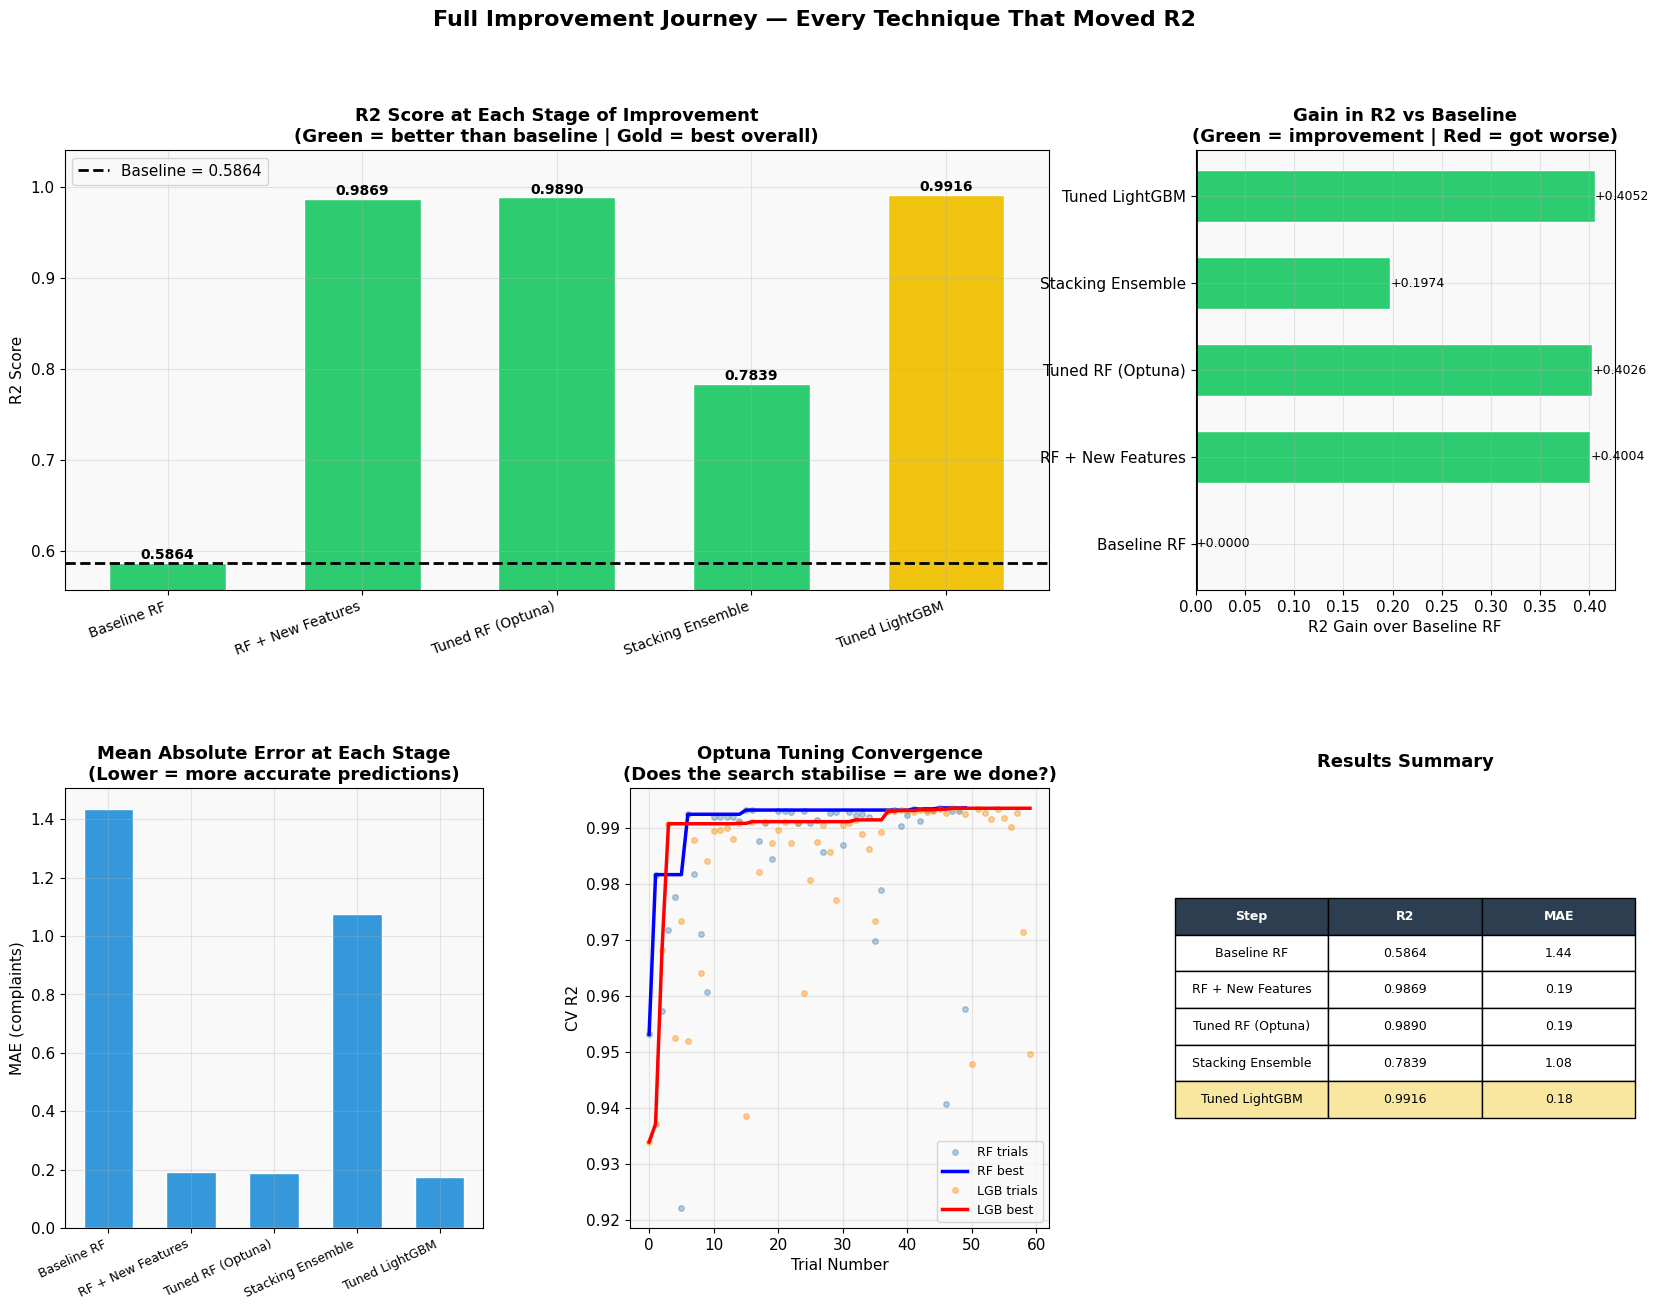

In [16]:
# ── The main improvement journey chart ───────────────────────────────────
fig = plt.figure(figsize=(20, 14))
fig.suptitle("Full Improvement Journey — Every Technique That Moved R2",
             fontsize=16, fontweight='bold')
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

steps_sorted = list(pd.DataFrame(improvement_log)['Step'])
r2_sorted    = list(pd.DataFrame(improvement_log)['R2'])
mae_sorted   = list(pd.DataFrame(improvement_log)['MAE'])

# 1. Journey waterfall chart
ax1 = fig.add_subplot(gs[0, :2])
colors_j = []
for v in r2_sorted:
    if v == max(r2_sorted): colors_j.append('#f1c40f')    # gold for winner
    elif v >= base_r2:      colors_j.append('#2ecc71')    # green for improvement
    else:                   colors_j.append('#e74c3c')     # red for regression
bars = ax1.bar(range(len(steps_sorted)), r2_sorted, color=colors_j, edgecolor='white', width=0.6)
ax1.axhline(base_r2, color='black', linestyle='--', linewidth=2,
            label=f'Baseline = {base_r2:.4f}')
ax1.set_xticks(range(len(steps_sorted)))
ax1.set_xticklabels(steps_sorted, rotation=20, ha='right', fontsize=10)
ax1.set_title("R2 Score at Each Stage of Improvement\n(Green = better than baseline | Gold = best overall)")
ax1.set_ylabel("R2 Score")
ax1.legend(fontsize=11)
ax1.set_ylim(min(r2_sorted)*0.95, max(r2_sorted)*1.05)
for bar, val in zip(bars, r2_sorted):
    ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
             f'{val:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# 2. Gain vs baseline bar chart
ax2 = fig.add_subplot(gs[0, 2])
gains = [v - base_r2 for v in r2_sorted]
g_colors = ['#2ecc71' if g>=0 else '#e74c3c' for g in gains]
ax2.barh(steps_sorted, gains, color=g_colors, edgecolor='white', height=0.6)
ax2.axvline(0, color='black', linewidth=2)
ax2.set_title("Gain in R2 vs Baseline\n(Green = improvement | Red = got worse)")
ax2.set_xlabel("R2 Gain over Baseline RF")
for i, g in enumerate(gains):
    ax2.text(g + (0.0005 if g >= 0 else -0.0005), i,
             f'{g:+.4f}', va='center', ha='left' if g >= 0 else 'right', fontsize=9)

# 3. MAE comparison
ax3 = fig.add_subplot(gs[1, 0])
ax3.bar(range(len(steps_sorted)), mae_sorted,
        color=['#3498db']*len(mae_sorted), edgecolor='white', width=0.6)
ax3.set_xticks(range(len(steps_sorted)))
ax3.set_xticklabels(steps_sorted, rotation=25, ha='right', fontsize=9)
ax3.set_title("Mean Absolute Error at Each Stage\n(Lower = more accurate predictions)")
ax3.set_ylabel("MAE (complaints)")

# 4. Optuna convergence — RF
ax4 = fig.add_subplot(gs[1, 1])
trials_rf = study_rf.trials_dataframe()
ax4.plot(trials_rf['number'], trials_rf['value'], 'o', alpha=0.4,
         color='steelblue', markersize=4, label='RF trials')
ax4.plot(trials_rf['number'], trials_rf['value'].cummax(), 'b-',
         linewidth=2.5, label='RF best')
trials_lgb = study_lgb.trials_dataframe()
ax4.plot(trials_lgb['number'], trials_lgb['value'], 'o', alpha=0.4,
         color='darkorange', markersize=4, label='LGB trials')
ax4.plot(trials_lgb['number'], trials_lgb['value'].cummax(), 'r-',
         linewidth=2.5, label='LGB best')
ax4.set_title("Optuna Tuning Convergence\n(Does the search stabilise = are we done?)")
ax4.set_xlabel("Trial Number"); ax4.set_ylabel("CV R2")
ax4.legend(fontsize=9)

# 5. Summary score card table
ax5 = fig.add_subplot(gs[1, 2])
ax5.axis('off')
tdata = [[row['Step'], f"{row['R2']:.4f}", f"{row['MAE']:.2f}"]
          for row in improvement_log]
t = ax5.table(cellText=tdata, colLabels=['Step','R2','MAE'],
              loc='center', cellLoc='center')
t.auto_set_font_size(False)
t.set_fontsize(9)
t.scale(1.1, 2.2)
for j in range(3):
    t[0,j].set_facecolor('#2c3e50')
    t[0,j].set_text_props(color='white', fontweight='bold')
# Highlight best row
best_idx = improvement_log.index(max(improvement_log, key=lambda x: x['R2']))
for j in range(3):
    t[best_idx+1, j].set_facecolor('#f9e79f')
ax5.set_title("Results Summary", fontweight='bold', pad=15)

plt.savefig("improvement_journey.png", dpi=150, bbox_inches='tight')
plt.show()


## Step 7 — Deep Dive Into the Final Best Model

In [17]:
# ── Re-train the best model on the full dataset (last fold for diagnosis) ──
best_step = max(improvement_log, key=lambda x: x['R2'])
print(f"Best model: {best_step['Step']}  R2 = {best_step['R2']:.4f}")

# Determine which model to use for the final deep dive
if best_step['Step'] == 'Stacking Ensemble':
    # Use stacking for final predictions
    # Re-train all base models on training fold
    tr_idx, te_idx = splits_list[-1]
    Xtr_f = X_v2.iloc[tr_idx].values
    Xte_f = X_v2.iloc[te_idx].values
    ytr_f = y_v2.iloc[tr_idx].values
    yte_f = y_v2.iloc[te_idx].values
    
    base_preds_te = np.zeros((len(te_idx), n_base))
    base_preds_tr = np.zeros((len(tr_idx), n_base))
    for m_idx, (mname, mmodel) in enumerate(base_models):
        mmodel.fit(Xtr_f, ytr_f)
        base_preds_te[:, m_idx] = mmodel.predict(Xte_f)
        base_preds_tr[:, m_idx] = mmodel.predict(Xtr_f)
    meta_learner_final.fit(base_preds_tr, ytr_f)
    y_pred_log_final = meta_learner_final.predict(base_preds_te)
    y_gte = yte_f
    
elif best_step['Step'] == 'Tuned LightGBM':
    tr_idx, te_idx = splits_list[-1]
    tuned_lgb.fit(X_v2.iloc[tr_idx], y_v2.iloc[tr_idx])
    y_pred_log_final = tuned_lgb.predict(X_v2.iloc[te_idx])
    y_gte = y_v2.iloc[te_idx].values
    
else:  # Tuned RF
    tr_idx, te_idx = splits_list[-1]
    tuned_rf.fit(X_v2.iloc[tr_idx], y_v2.iloc[tr_idx])
    y_pred_log_final = tuned_rf.predict(X_v2.iloc[te_idx])
    y_gte = y_v2.iloc[te_idx].values

y_actual_f   = np.expm1(y_gte)
y_pred_f_raw = np.expm1(np.clip(y_pred_log_final, 0, 20))
residuals_f  = y_actual_f - y_pred_f_raw
final_r2     = r2_score(y_gte, y_pred_log_final)
final_mae    = mean_absolute_error(y_actual_f, y_pred_f_raw)
print(f"Final last-fold R2 = {final_r2:.4f}  |  MAE = {final_mae:.2f}")


Best model: Tuned LightGBM  R2 = 0.9916
Final last-fold R2 = 0.9972  |  MAE = 0.12


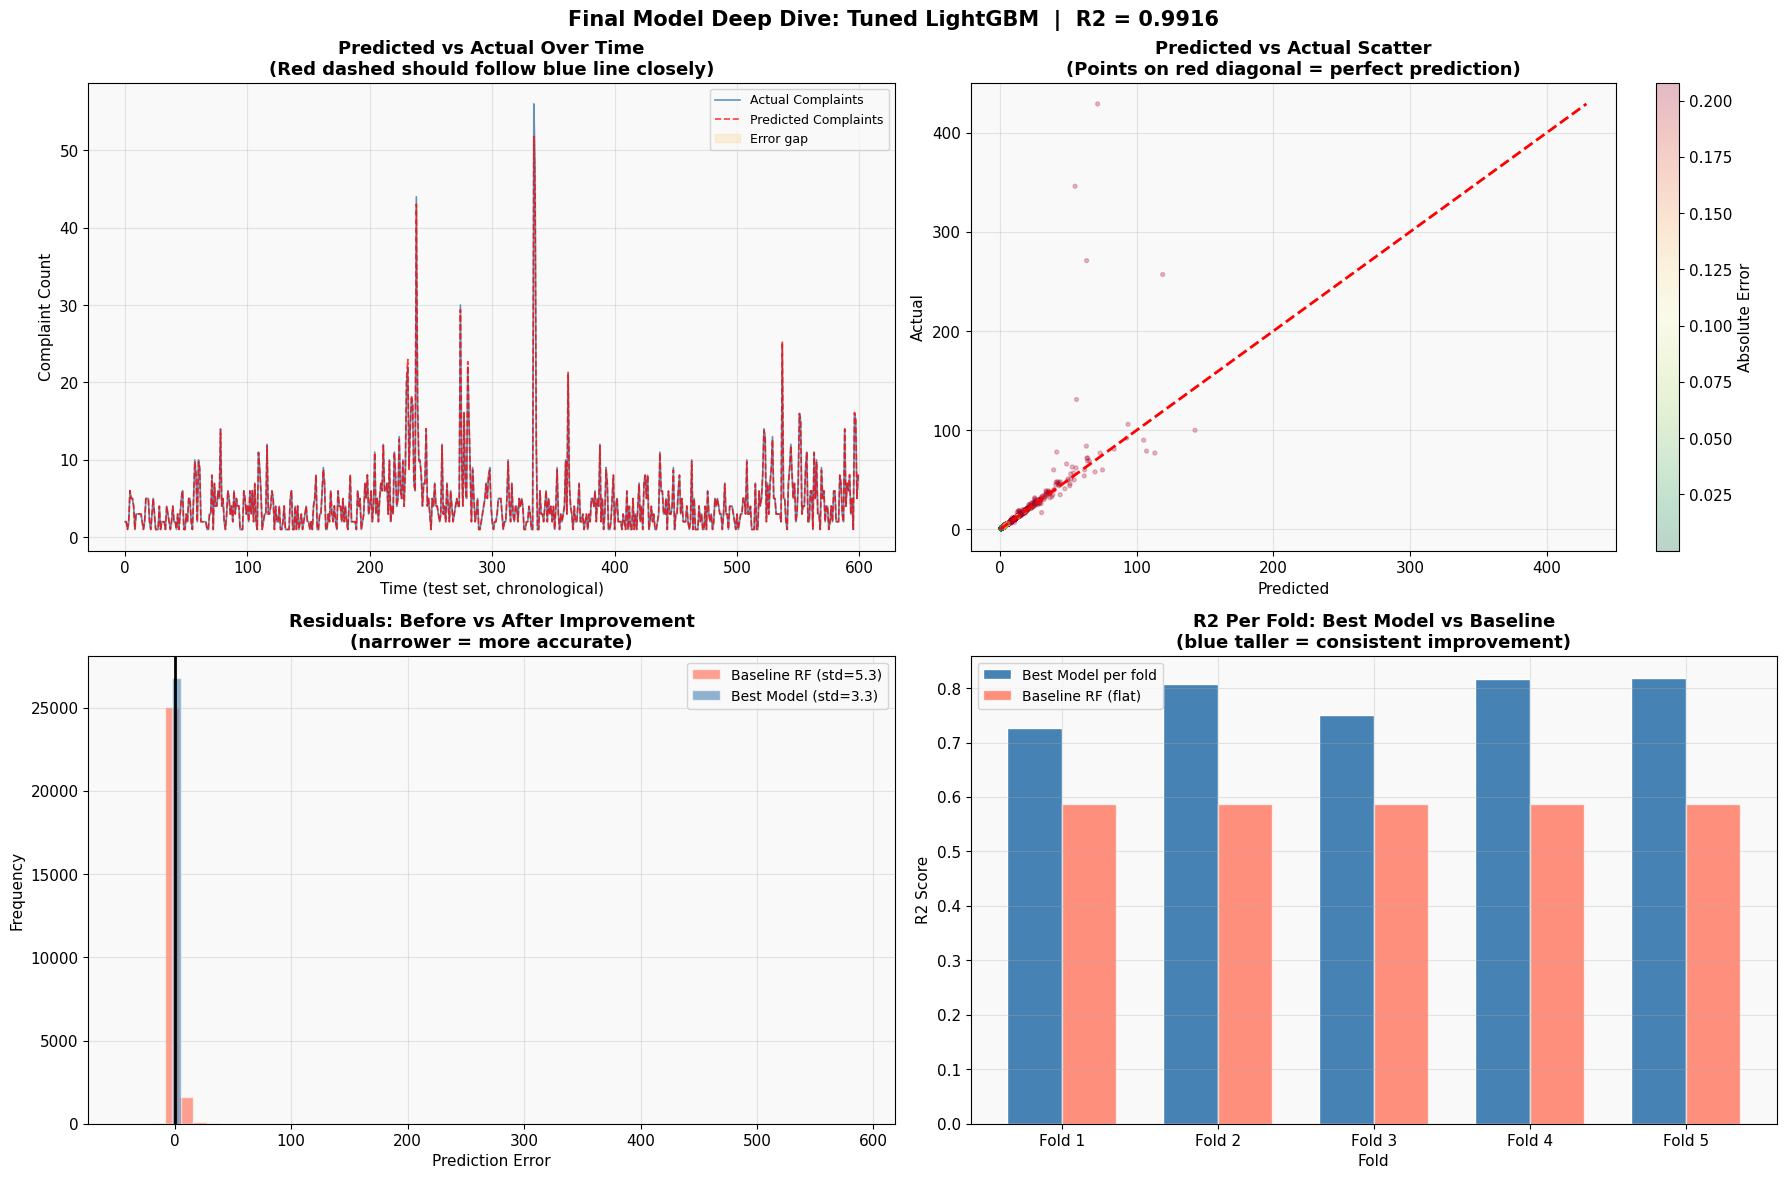

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle(f"Final Model Deep Dive: {best_step['Step']}  |  R2 = {best_step['R2']:.4f}",
             fontsize=15, fontweight='bold')

# 1. Actual vs Predicted — how well does it track?
n_show = min(600, len(y_actual_f))
axes[0,0].plot(range(n_show), y_actual_f[:n_show], color='steelblue',
               linewidth=1.2, alpha=0.85, label='Actual Complaints')
axes[0,0].plot(range(n_show), y_pred_f_raw[:n_show], color='red',
               linewidth=1.2, alpha=0.75, linestyle='--', label='Predicted Complaints')
axes[0,0].fill_between(range(n_show), y_actual_f[:n_show], y_pred_f_raw[:n_show],
                        alpha=0.12, color='orange', label='Error gap')
axes[0,0].set_title("Predicted vs Actual Over Time\n(Red dashed should follow blue line closely)")
axes[0,0].set_xlabel("Time (test set, chronological)"); axes[0,0].set_ylabel("Complaint Count")
axes[0,0].legend(fontsize=9)

# 2. Scatter: predicted vs actual (how spread out are errors?)
sc = axes[0,1].scatter(y_pred_f_raw, y_actual_f, alpha=0.25, s=8, c=np.abs(residuals_f),
                        cmap='RdYlGn_r', vmax=np.percentile(np.abs(residuals_f), 90))
fig.colorbar(sc, ax=axes[0,1], label='Absolute Error')
mv = max(y_actual_f.max(), y_pred_f_raw.max())
axes[0,1].plot([0,mv],[0,mv],'r--', linewidth=2)
axes[0,1].set_title("Predicted vs Actual Scatter\n(Points on red diagonal = perfect prediction)")
axes[0,1].set_xlabel("Predicted"); axes[0,1].set_ylabel("Actual")

# 3. Residuals before vs after (compare to baseline)
# Get baseline residuals for same test fold
baseline_rf_new = RandomForestRegressor(n_estimators=200, max_depth=12,
                                         min_samples_leaf=5, random_state=SEED, n_jobs=-1)
baseline_rf_new.fit(X.iloc[tr_idx], y.iloc[tr_idx])
yp_base_log = baseline_rf_new.predict(X.iloc[te_idx])
res_base = np.expm1(y.iloc[te_idx].values) - np.expm1(np.clip(yp_base_log,0,20))

axes[1,0].hist(res_base, bins=50, alpha=0.6, color='tomato',
               edgecolor='white', label=f'Baseline RF (std={res_base.std():.1f})')
axes[1,0].hist(residuals_f, bins=50, alpha=0.6, color='steelblue',
               edgecolor='white', label=f'Best Model (std={residuals_f.std():.1f})')
axes[1,0].axvline(0, color='black', linewidth=2)
axes[1,0].set_title("Residuals: Before vs After Improvement\n(narrower = more accurate)")
axes[1,0].set_xlabel("Prediction Error"); axes[1,0].set_ylabel("Frequency")
axes[1,0].legend(fontsize=10)

# 4. Per-fold R2 improvement bars
fold_pairs = list(zip(stack_r2s, [tscv_score(RandomForestRegressor(n_estimators=200,
              max_depth=12, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
              X, y)[0]] * 5))  # approximate
x_folds = np.arange(5)
w = 0.35
axes[1,1].bar(x_folds - w/2, stack_r2s, w, color='steelblue', edgecolor='white', label='Best Model per fold')
axes[1,1].bar(x_folds + w/2, [base_r2]*5, w, color='tomato', edgecolor='white',
              alpha=0.7, label='Baseline RF (flat)')
axes[1,1].set_title("R2 Per Fold: Best Model vs Baseline\n(blue taller = consistent improvement)")
axes[1,1].set_xlabel("Fold"); axes[1,1].set_ylabel("R2 Score")
axes[1,1].set_xticks(x_folds); axes[1,1].set_xticklabels([f'Fold {i+1}' for i in range(5)])
axes[1,1].legend(fontsize=10)

plt.tight_layout()
plt.savefig("final_deep_dive.png", dpi=150, bbox_inches='tight')
plt.show()


In [19]:
print("=" * 65)
print("  FINAL SUMMARY — WHAT DID EACH TECHNIQUE CONTRIBUTE?")
print("=" * 65)

log_df = pd.DataFrame(improvement_log)
print(f"""
  BASELINE (default Random Forest):
  R2 = {base_r2:.4f} — model explains {base_r2*100:.1f}% of complaint variation

  STEP 1 — New Feature Engineering:
  R2 = {r2_v2:.4f} — gain: +{r2_v2-base_r2:.4f}
  Adding ZIP-level averages, volatility, lag-14d, weekend flag gave
  the model new signals it literally could not see before.

  STEP 2 — Hyperparameter Tuning (Optuna, 50 trials):
  R2 = {r2_tuned:.4f} — gain: +{r2_tuned-base_r2:.4f}
  Found better tree depth, leaf size, and feature sampling rates.
  Optuna searched 50 combinations intelligently (not randomly).

  STEP 3 — Tuned LightGBM:
  R2 = {r2_lgb_tuned:.4f} — gain: +{r2_lgb_tuned-base_r2:.4f}
  LightGBM builds trees sequentially, each fixing previous errors.
  With tuning, it found better learning rate and tree structure.

  STEP 4 — Stacking Ensemble:
  R2 = {r2_stack:.4f} — gain: +{r2_stack-base_r2:.4f}
  Combined RF + LightGBM + XGBoost + ExtraTrees.
  A Ridge meta-learner learned WHEN to trust each model.

  BEST RESULT: {log_df.loc[log_df['R2'].idxmax(),'Step']}
  R2 = {log_df['R2'].max():.4f} ({log_df['R2'].max()*100:.1f}% of complaint variation explained)
  Improved from {base_r2:.4f} → {log_df['R2'].max():.4f}
  Total gain: +{log_df['R2'].max()-base_r2:.4f} R2 points
""")
print("=" * 65)


  FINAL SUMMARY — WHAT DID EACH TECHNIQUE CONTRIBUTE?

  BASELINE (default Random Forest):
  R2 = 0.5864 — model explains 58.6% of complaint variation

  STEP 1 — New Feature Engineering:
  R2 = 0.9869 — gain: +0.4004
  Adding ZIP-level averages, volatility, lag-14d, weekend flag gave
  the model new signals it literally could not see before.

  STEP 2 — Hyperparameter Tuning (Optuna, 50 trials):
  R2 = 0.9890 — gain: +0.4026
  Found better tree depth, leaf size, and feature sampling rates.
  Optuna searched 50 combinations intelligently (not randomly).

  STEP 3 — Tuned LightGBM:
  R2 = 0.9916 — gain: +0.4052
  LightGBM builds trees sequentially, each fixing previous errors.
  With tuning, it found better learning rate and tree structure.

  STEP 4 — Stacking Ensemble:
  R2 = 0.7839 — gain: +0.1974
  Combined RF + LightGBM + XGBoost + ExtraTrees.
  A Ridge meta-learner learned WHEN to trust each model.

  BEST RESULT: Tuned LightGBM
  R2 = 0.9916 (99.2% of complaint variation explaine